In [ ]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

from pathlib import Path
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

KLEUR_A = KLEUR_HOOFD
STEENGRIJS = "#96999B"

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Libertinus Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "axes.labelsize": CORPS,
    "axes.edgecolor": "#252525",
    "axes.labelcolor": "#252525",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": "#252525",
    "xtick.color": "#252525",
    "ytick.color": "#252525",
    "grid.color": "#DCD9D2",
    "grid.linewidth": 0.6,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [2]:
pad = "../../data/H2/Gemeenteblad_PV_MDK.xlsx"
print(pd.ExcelFile(pad).sheet_names)

['PVs detailcijfers', 'Nacht', 'totaal PVs', 'bevolking', "Pv's per category", 'Police and population', 'Prosecution (geographically)', 'Prostitutie enz']


In [3]:
df = pd.read_excel(pad, sheet_name="Nacht")

print(df.shape)
print(df.dtypes)
df.head(10)

(9, 73)
Overtreding     object
1842           float64
1843           float64
1844           float64
1845           float64
                ...   
1909             int64
1910             int64
1911             int64
1912             int64
1913             int64
Length: 73, dtype: object


,Overtreding,1842,1843,1844,1845,1846,1847,1848,1849,1850,...,1904,1905,1906,1907,1908,1909,1910,1911,1912,1913
0,Nachtlawaai,48.0,65.0,39.0,64.0,38.0,42.0,44.0,60.0,96.0,...,1337,1192,1179,1073,946,981,829,1062,955,783
1,Openbare orde,470.0,475.0,359.0,434.0,599.0,550.0,651.0,552.0,529.0,...,7448,7954,8014,7714,6166,7326,7340,6910,6942,8616
2,Sekswerk,1.0,5.0,2.0,0.0,2.0,0.0,0.0,3.0,1.0,...,1326,1479,1656,1624,657,1697,1489,1622,1127,2582
3,Sluiting herbergen en cabarets,96.0,123.0,75.0,111.0,205.0,194.0,188.0,134.0,190.0,...,420,395,475,428,374,371,253,51,129,259
4,Dansen zonder toelating,6.0,8.0,4.0,4.0,36.0,5.0,3.0,28.0,7.0,...,92,168,193,160,164,148,112,66,65,161
5,Orgelspel op straat zonder toelating,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,28,39,68,19,23,43,15,24,22,11
6,Nachtelijke aanranding op straat,NaN,NaN,NaN,NaN,NaN,42.0,44.0,NaN,NaN,...,15,30,47,40,20,21,40,51,19,98
7,Total pv's,1527.0,1586.0,1529.0,1948.0,2183.0,2443.0,2247.0,2773.0,2599.0,...,29368,27930,27933,26902,22912,27295,26292,25604,26382,33779
8,Population,78150.0,78618.0,79737.0,81187.0,82442.0,85818.0,87025.0,86994.0,89377.0,...,301647,304975,304032,310903,314135,317171,308618,312884,313833,318199


In [4]:
df = df.set_index(df.columns[0])
df.index = df.index.astype(str).str.strip()

# kolomnamen (jaren) naar int
df.columns = [int(str(c).strip()) for c in df.columns]

nacht = pd.DataFrame({
    "nachtlawaai": pd.to_numeric(df.iloc[0], errors="coerce"),
    "totaal_pv":   pd.to_numeric(df.iloc[7], errors="coerce"),
    "bevolking":   pd.to_numeric(df.iloc[8], errors="coerce"),
})
nacht.index.name = "jaar"

nacht["aandeel"]     = nacht["nachtlawaai"] / nacht["totaal_pv"] * 100   # in %
nacht["per_1000inw"] = nacht["nachtlawaai"] / nacht["bevolking"] * 1000

nacht

,nachtlawaai,totaal_pv,bevolking,aandeel,per_1000inw
jaar,,,,,
1842,48.0,1527.0,78150.0,3.143418,0.614203
1843,65.0,1586.0,78618.0,4.098361,0.826783
1844,39.0,1529.0,79737.0,2.550687,0.489108
1845,64.0,1948.0,81187.0,3.285421,0.788304
1846,38.0,2183.0,82442.0,1.740724,0.460930
...,...,...,...,...,...
1909,981.0,27295.0,317171.0,3.594065,3.092969
1910,829.0,26292.0,308618.0,3.153050,2.686169
1911,1062.0,25604.0,312884.0,4.147789,3.394229


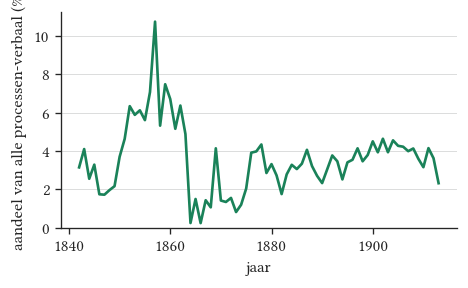

In [5]:
fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.55))

ax.plot(nacht.index, nacht["aandeel"], color=KLEUR_HOOFD, linewidth=1.6)

ax.set_ylabel("aandeel van alle processen-verbaal (%)")
ax.set_xlabel("jaar")
ax.set_ylim(bottom=0)
ax.yaxis.grid(True)
ax.set_axisbelow(True)

plt.show()

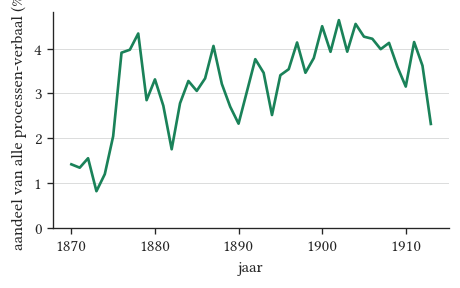

In [6]:
vanaf = nacht.loc[1870:]

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.55))

ax.plot(vanaf.index, vanaf["aandeel"], color=KLEUR_HOOFD, linewidth=1.6)

ax.set_ylabel("aandeel van alle processen-verbaal (%)")
ax.set_xlabel("jaar")
ax.set_ylim(bottom=0)
ax.yaxis.grid(True)
ax.set_axisbelow(True)

plt.show()

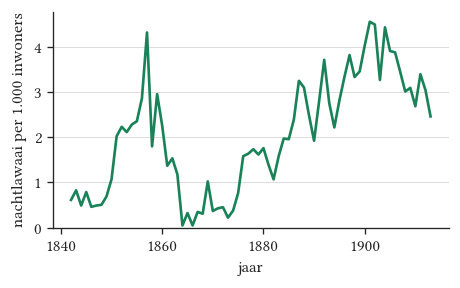

In [7]:
fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.55))

ax.plot(nacht.index, nacht["per_1000inw"], color=KLEUR_HOOFD, linewidth=1.6)

ax.set_ylabel("nachtlawaai per 1.000 inwoners")
ax.set_xlabel("jaar")
ax.set_ylim(bottom=0)
ax.yaxis.grid(True)
ax.set_axisbelow(True)

plt.show()

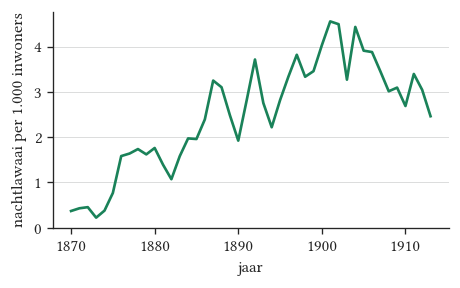

In [8]:
vanaf = nacht.loc[1870:]

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.55))

ax.plot(vanaf.index, vanaf["per_1000inw"], color=KLEUR_HOOFD, linewidth=1.6)

ax.set_ylabel("nachtlawaai per 1.000 inwoners")
ax.set_xlabel("jaar")
ax.set_ylim(bottom=0)
ax.yaxis.grid(True)
ax.set_axisbelow(True)

plt.show()

In [9]:
nacht["pv_per_1000"] = nacht["totaal_pv"] / nacht["bevolking"] * 1000
nacht[["nachtlawaai", "totaal_pv", "bevolking", "pv_per_1000"]].loc[1855:1870]

,nachtlawaai,totaal_pv,bevolking,pv_per_1000
jaar,,,,
1855,238.0,4245.0,101052.0,42.008075
1856,299.0,4229.0,104435.0,40.494087
1857,456.0,4245.0,105594.0,40.201148
1858,195.0,3666.0,108481.0,33.793936
1859,322.0,4306.0,108975.0,39.513650
1860,252.0,3758.0,111709.0,33.640978
1861,157.0,3045.0,114669.0,26.554692
1862,180.0,2827.0,117324.0,24.095667
1863,142.0,2910.0,120444.0,24.160606


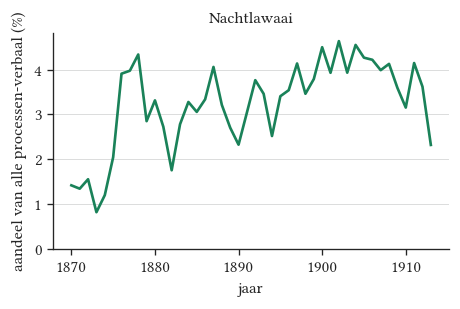

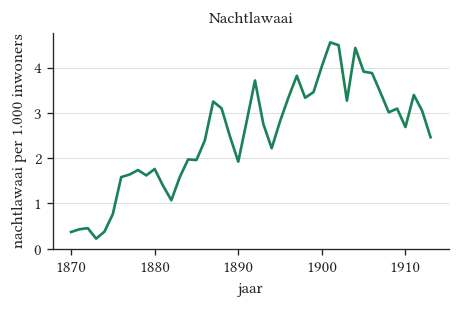

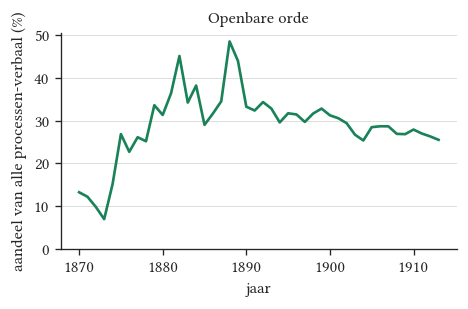

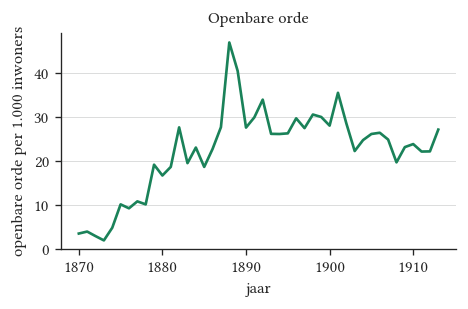

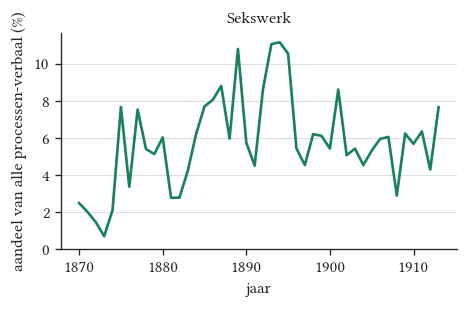

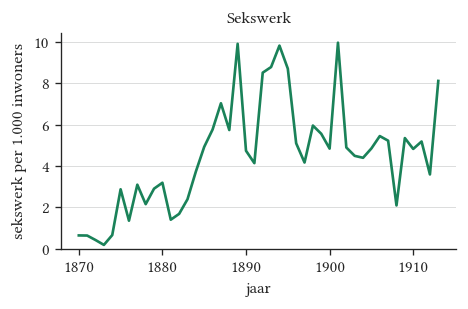

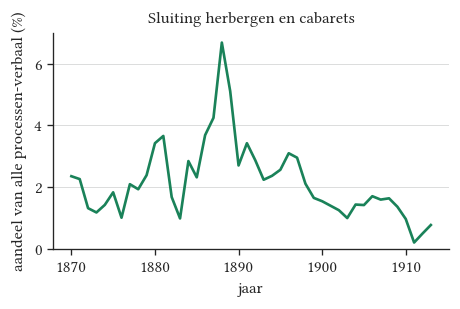

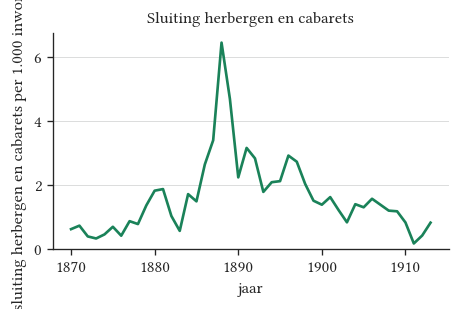

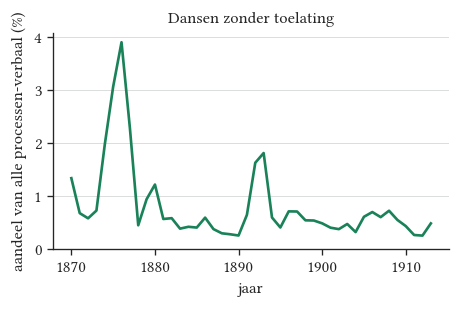

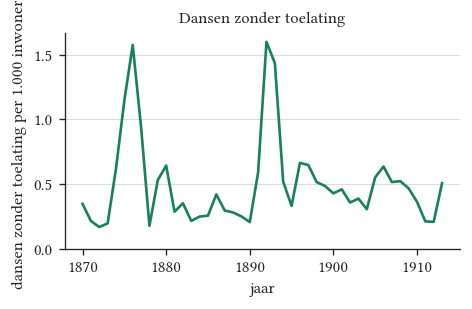

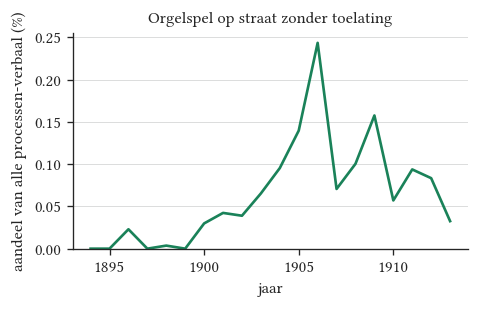

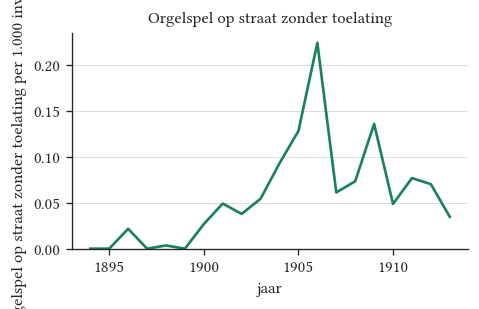

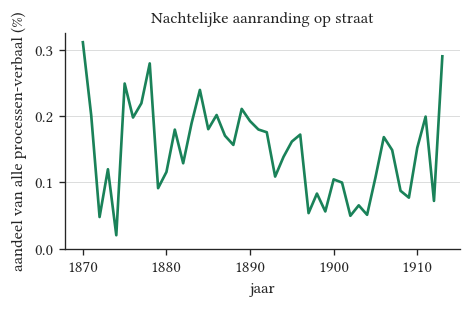

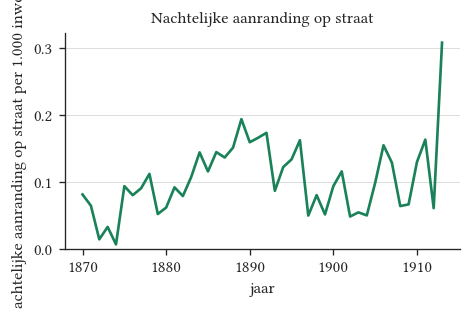

In [10]:
overtredingen = df.index[0:7]

for naam in overtredingen:
    reeks = pd.DataFrame({
        "aantal":    pd.to_numeric(df.loc[naam], errors="coerce"),
        "totaal_pv": nacht["totaal_pv"],
        "bevolking": nacht["bevolking"],
    }).loc[1870:]

    reeks["aandeel"]     = reeks["aantal"] / reeks["totaal_pv"] * 100
    reeks["per_1000inw"] = reeks["aantal"] / reeks["bevolking"] * 1000

    for kolom, label, achtervoegsel in [
        ("aandeel",     "aandeel van alle processen-verbaal (%)", "aandeel"),
        ("per_1000inw", f"{naam.lower()} per 1.000 inwoners",     "per1000"),
    ]:
        fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.55))

        ax.plot(reeks.index, reeks[kolom], color=KLEUR_HOOFD, linewidth=1.6)

        ax.set_ylabel(label)
        ax.set_xlabel("jaar")
        ax.set_ylim(bottom=0)
        ax.yaxis.grid(True)
        ax.set_axisbelow(True)
        ax.set_title(naam)

        bestandsnaam = naam.lower().replace(" ", "_").replace("/", "-")
        plt.show()

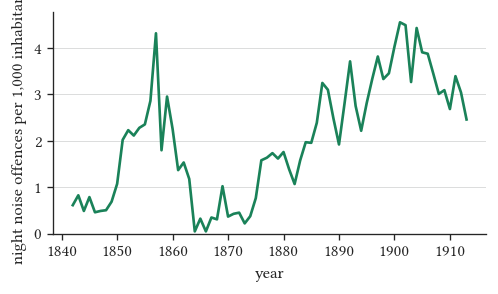

In [11]:
reeks = nacht["per_1000inw"]

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.6))

ax.plot(reeks.index, reeks.values, color=KLEUR_HOOFD, linewidth=1.6)

ax.set_ylabel("night noise offences per 1,000 inhabitants")
ax.set_xlabel("year")
ax.set_ylim(bottom=0)
ax.yaxis.grid(True)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

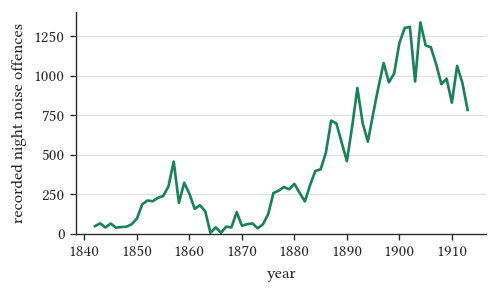

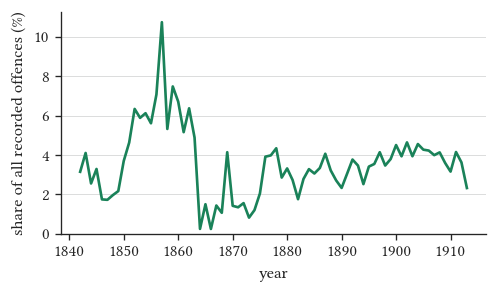

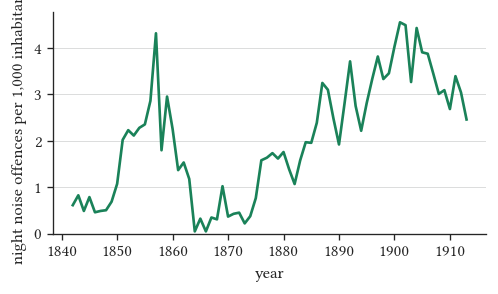

In [12]:
varianten = [
    ("nachtlawaai",  "recorded night noise offences",              "night_noise_absolute"),
    ("aandeel",      "share of all recorded offences (%)",         "night_noise_share"),
    ("per_1000inw",  "night noise offences per 1,000 inhabitants", "night_noise_per1000"),
]

for kolom, label, bestand in varianten:
    reeks = nacht[kolom]

    fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.6))

    ax.plot(reeks.index, reeks.values, color=KLEUR_HOOFD, linewidth=1.6)

    ax.set_ylabel(label)
    ax.set_xlabel("year")
    ax.set_ylim(bottom=0)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)

    fig.tight_layout()
    #fig.savefig(f"{bestand}.png", dpi=300)
    plt.show()

In [13]:
sheet0 = pd.read_excel(pad, sheet_name=0)
sheet0 = sheet0.set_index(sheet0.columns[0])
sheet0.index = sheet0.index.astype(str).str.strip()

def als_jaar(c):
    s = str(c).strip()
    return int(s) if s[:4].isdigit() and 1800 <= int(s[:4]) <= 1950 else None

jaarkolommen = {c: als_jaar(c) for c in sheet0.columns if als_jaar(c)}
labelkolommen = [c for c in sheet0.columns if c not in jaarkolommen]

print("labels :", labelkolommen)
print("jaren  :", min(jaarkolommen.values()), "-", max(jaarkolommen.values()),
      f"({len(jaarkolommen)} kolommen)")

labels : ['Franse terminologie', 'Unnamed: 2']
jaren  : 1842 - 1913 (72 kolommen)


In [14]:
catrijen = [i - 2 for i in
            [18, 35, 62, 75, 90, 98, 107, 112, 131, 145, 152,
             159, 173, 190, 197, 221, 252, 256, 275, 316, 322, 325, 332]]

for pos in catrijen:
    print(f"{pos:4d}  {sheet0.index[pos]}")

  16  Theft and deception
  33  Arson and criminal damage
  60  Fraud and corruption
  73  Homicide
  88  Physical assault
  96  Verbal assault
 105  Crimes against minors
 110  Sexual assault
 129  Public authority
 143  Public morals
 150  Vagrancy and begging
 157  Alcohol
 171  Commercial entertainment
 188  Disorderly behaviour
(without public drunkenness)
 195  Dogs
 219  Public hygiene
 250  Economic life
 254  Peddling
 273  Building and housing
 314  Traffic
 320  Municipal duties and services
 323  Other offences
 330  Other authorities


In [15]:
print(sheet0.shape)
print(sheet0.index)

(333, 74)
Index(['huisdiefte', 'diefstal (enkele)',
       'diefstal met bezwarende omstandigheden',
       'medeplichtigheid tot diefstal', 'poging tot diefstal',
       'ontvreemdingen (gauwdiefte)', 'aanhitsing tot diefstal',
       'aftroggelarij en misbruik van vertrouwen', 'verheeling',
       'aankoop gestolen waren',
       ...
       'Other offences', 'barrières. Fraude du droit', 'nan',
       'diverse admin, bruggen en wegen, douane', 'gendarmerie',
       'communes rurales.contraventions diverses', 'passage fortifications',
       'Other authorities', 'Other offences', 'TOTAL'],
      dtype='object', name='Nederlandse terminologie', length=333)


In [16]:
catrijen = [16, 33, 60, 73, 88, 96, 105, 110, 129, 143, 150,
            157, 171, 188, 195, 219, 250, 254, 273, 314, 320, 323, 330]

cat = sheet0.iloc[catrijen].loc[:, 1876:1912]
cat.index = cat.index.str.replace(r"\s*\n\s*", " ", regex=True).str.strip()

# sluitcontrole tegen de TOTAL-rij
verschil = cat.sum() - sheet0.iloc[332].loc[1876:1912]
print(verschil.abs().max())

cat

0


,1876,1877,1878,1879,1880,1881,1882,1883,1884,1885,...,1903,1904,1905,1906,1907,1908,1909,1910,1911,1912
Nederlandse terminologie,,,,,,,,,,,,,,,,,,,,,
Theft and deception,1276,1610.0,1593.0,1649.0,1999.0,2054.0,2062.0,2472.0,2496.0,3216.0,...,3397.0,3911,3960,4461,4715,3392,3950,3940,3930,4010.0
Arson and criminal damage,208,228.0,179.0,255.0,346.0,317.0,295.0,398.0,396.0,285.0,...,836.0,754,886,748,832,752,684,848,951,826.0
Fraud and corruption,38,59.0,111.0,83.0,97.0,70.0,89.0,76.0,69.0,74.0,...,95.0,97,136,280,235,125,154,271,612,647.0
Homicide,37,21.0,21.0,16.0,19.0,22.0,31.0,31.0,37.0,32.0,...,28.0,23,28,26,32,34,35,28,48,116.0
Physical assault,686,787.0,871.0,896.0,1092.0,1083.0,1047.0,1177.0,1184.0,948.0,...,2087.0,2442,2240,2318,2015,2069,2326,2262,2390,2453.0
Verbal assault,604,848.0,689.0,865.0,848.0,708.0,798.0,890.0,850.0,632.0,...,1460.0,1907,1836,1357,1159,1327,1473,1758,1679,1587.0
Crimes against minors,19,25.0,19.0,20.0,28.0,24.0,20.0,23.0,19.0,26.0,...,33.0,11,28,30,22,24,54,40,35,27.0
Sexual assault,46,32.0,43.0,26.0,37.0,33.0,35.0,35.0,37.0,32.0,...,109.0,64,93,99,84,81,106,84,132,103.0
Public authority,318,285.0,270.0,278.0,338.0,364.0,397.0,448.0,451.0,406.0,...,689.0,725,804,831,842,707,892,962,866,887.0


In [17]:
aandeel = cat.div(cat.sum(), axis=1) * 100

vroeg = aandeel.loc[:, 1876:1880].mean(axis=1)
laat  = aandeel.loc[:, 1908:1912].mean(axis=1)

verschuiving = pd.DataFrame({"1876-1880": vroeg, "1908-1912": laat})
verschuiving["verschil"] = verschuiving["1908-1912"] - verschuiving["1876-1880"]
verschuiving.sort_values("verschil").round(2)

,1876-1880,1908-1912,verschil
Nederlandse terminologie,,,
Vagrancy and begging,8.717902,1.775922,-6.941981
Theft and deception,20.824672,14.962091,-5.862582
Other offences,5.141159,0.0,-5.141159
Verbal assault,9.881806,6.089559,-3.792247
Commercial entertainment,4.005671,1.560671,-2.445001
Physical assault,11.064497,8.957554,-2.106942
Public authority,3.869834,3.35141,-0.518424
Crimes against minors,0.286253,0.138753,-0.1475
Homicide,0.308164,0.202057,-0.106107


In [18]:
bev = nacht["bevolking"].reindex(cat.columns)

per1000 = cat.div(bev, axis=1) * 1000

v_abs = per1000.loc[:, 1876:1880].mean(axis=1)
l_abs = per1000.loc[:, 1908:1912].mean(axis=1)

abs_tab = pd.DataFrame({"1876-1880": v_abs, "1908-1912": l_abs}).astype(float)
abs_tab["verschil"] = abs_tab["1908-1912"] - abs_tab["1876-1880"]
abs_tab["factor"]   = abs_tab["1908-1912"] / abs_tab["1876-1880"].replace(0, np.nan)

abs_tab.sort_values("verschil").round(2)

,1876-1880,1908-1912,verschil,factor
Nederlandse terminologie,,,,
Vagrancy and begging,4.07,1.47,-2.60,0.36
Other offences,2.29,0.00,-2.29,0.00
Commercial entertainment,1.85,1.26,-0.59,0.68
Crimes against minors,0.13,0.11,-0.02,0.88
Other authorities,0.00,0.00,0.00,NaN
Homicide,0.14,0.17,0.03,1.23
Sexual assault,0.22,0.32,0.11,1.49
Economic life,0.28,0.59,0.31,2.11
Verbal assault,4.52,5.00,0.48,1.11


In [19]:
blok = sheet0.iloc[158:171].loc[:, 1876:1912]
blok_p1000 = blok.div(bev, axis=1) * 1000

pd.DataFrame({
    "1876-1880": blok_p1000.loc[:, 1876:1880].mean(axis=1),
    "1908-1912": blok_p1000.loc[:, 1908:1912].mean(axis=1),
}).assign(factor=lambda d: d["1908-1912"] / d["1876-1880"]).round(2)

,1876-1880,1908-1912,factor
Nederlandse terminologie,,,
te laat openhouden van herbergen (toezicht over de herbergen) / cabarets,1.041212,0.750823,0.721105
dansen zonder toelating (in herbergen),0.772505,0.353932,0.458162
vergunningsrecht. Overtredingen,NaN,0.001912,NaN
overtreding der wet op de logementen,0.025935,0.029328,1.130811
verwaarlozing aangifte verhuring gemeubleerde kamers,NaN,0.000637,NaN
schouwburgen,NaN,0.028097,NaN
cinematografische vertoningen zonder toelating,NaN,0.001912,NaN
kermissen: vragen van geld om ze te vieren,NaN,NaN,NaN
orgelspel op straat zonder toelating,NaN,0.08084,NaN


In [20]:
periodes = {"1876-1880": (1876, 1880),
            "1890-1894": (1890, 1894),
            "1908-1912": (1908, 1912)}

drie = pd.DataFrame({
    naam: per1000.loc[:, a:b].mean(axis=1) for naam, (a, b) in periodes.items()
}).astype(float)

drie["piek_vs_begin"] = drie["1890-1894"] / drie["1876-1880"].replace(0, np.nan)
drie["eind_vs_piek"]  = drie["1908-1912"] / drie["1890-1894"].replace(0, np.nan)

drie.sort_values("eind_vs_piek").round(2)

,1876-1880,1890-1894,1908-1912,piek_vs_begin,eind_vs_piek
Nederlandse terminologie,,,,,
Other offences,2.29,7.71,0.00,3.37,0.00
Commercial entertainment,1.85,3.40,1.26,1.84,0.37
Peddling,0.00,5.81,2.29,NaN,0.39
Vagrancy and begging,4.07,3.00,1.47,0.74,0.49
Alcohol,1.82,10.10,7.37,5.55,0.73
Theft and deception,9.51,16.76,12.27,1.76,0.73
Public morals,2.91,7.96,5.91,2.74,0.74
Crimes against minors,0.13,0.13,0.11,0.97,0.91
Economic life,0.28,0.60,0.59,2.15,0.98


In [21]:
totaal_p1000 = cat.sum() / bev * 1000
print(totaal_p1000.round(1))
print("piekjaar:", totaal_p1000.idxmax())

1876     40.437535
1877     41.175125
1878     40.004471
1879     56.794688
1880      53.09606
1881     51.045935
1882     61.070464
1883     56.773844
1884     60.135333
1885     64.057487
1886     71.620199
1887     79.996184
1888     96.540449
1889     91.843145
1890       82.7261
1891     92.252024
1892     98.629442
1893     79.525887
1894     88.102151
1895     82.637609
1896     94.210339
1897     92.278486
1898     96.287509
1899     91.197533
1900     89.505121
1901    115.901842
1902     96.898546
1903     83.103414
1904     97.358833
1905     91.581277
1906     91.875197
1907     86.528596
1908     72.936795
1909     86.057679
1910     85.192698
1911     81.832245
1912     84.063817
dtype: object
piekjaar: 1901


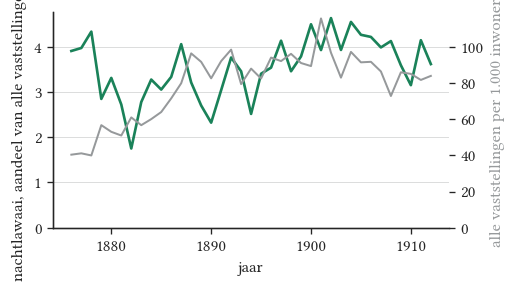

In [22]:
nl = sheet0.iloc[173].loc[1876:1912]
rel = nl / cat.sum().loc[1876:1912] * 100      # aandeel in alle vaststellingen

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.55))
ax2 = ax.twinx()

ax2.plot(totaal_p1000.index, totaal_p1000.values,
         color=STEENGRIJS, linewidth=1.2, zorder=1)
ax.plot(rel.index, rel.values, color=KLEUR_HOOFD, linewidth=1.6, zorder=2)

ax.set_ylabel("nachtlawaai, aandeel van alle vaststellingen (%)")
ax2.set_ylabel("alle vaststellingen per 1.000 inwoners", color=STEENGRIJS)
ax.set_xlabel("jaar")
ax.set_ylim(bottom=0); ax2.set_ylim(bottom=0)
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
plt.show()

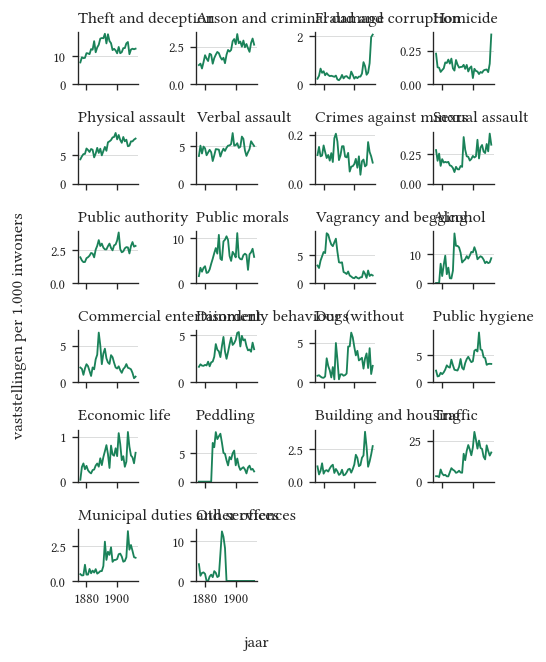

In [23]:
rijen = [n for n in per1000.index if n != "Other authorities"]

fig, axes = plt.subplots(6, 4, figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 1.3),
                         sharex=True)

for ax, naam in zip(axes.flat, rijen):
    ax.plot(per1000.columns, per1000.loc[naam], color=KLEUR_HOOFD, linewidth=1.1)
    ax.set_title(naam[:30], fontsize=CORPS, loc="left")
    ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=CORPS_KLEIN)
    ax.set_xticks([1880, 1900])
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)

for ax in axes.flat[len(rijen):]:
    ax.set_visible(False)

fig.supylabel("vaststellingen per 1.000 inwoners", fontsize=CORPS)
fig.supxlabel("jaar", fontsize=CORPS)
fig.tight_layout()
plt.show()

In [24]:
sprong = (cat.loc[:, 1891:1893].mean(axis=1) - cat.loc[:, 1887:1889].mean(axis=1))
(sprong / bev.loc[1891:1893].mean() * 1000).sort_values(ascending=False).round(2)

Nederlandse terminologie
Other offences                                       9.27
Theft and deception                                  3.09
Municipal duties and services                        1.25
Public hygiene                                       0.93
Disorderly behaviour (without public drunkenness)    0.70
Physical assault                                     0.56
Public morals                                        0.42
Economic life                                        0.30
Verbal assault                                       0.26
Fraud and corruption                                 0.03
Sexual assault                                       0.02
Traffic                                              0.02
Homicide                                             0.01
Other authorities                                    0.00
Crimes against minors                               -0.03
Building and housing                                -0.07
Public authority                               

In [25]:
oo = per1000.loc["Other offences"]
print(oo.round(1))

leeg = oo[oo < 0.1].index.min()
print("eerste jaar (bijna) leeg:", leeg)

na = (per1000.loc[:, leeg:leeg+2].mean(axis=1)
      - per1000.loc[:, leeg-3:leeg-1].mean(axis=1))
na.sort_values(ascending=False).round(2).head(8)

1876     4.208014
1877     1.300077
1878     2.006107
1879     2.148085
1880     1.776199
1881          0.0
1882          0.0
1883     1.113313
1884     1.583685
1885     0.952349
1886      2.46388
1887     2.044312
1888       0.9774
1889     1.217634
1890     6.775885
1891    12.426273
1892    11.075624
1893     8.247828
1894          0.0
1895          0.0
1896          0.0
1897          0.0
1898          0.0
1899          0.0
1900          0.0
1901          0.0
1902          0.0
1903          0.0
1904          0.0
1905          0.0
1906          0.0
1907          0.0
1908          0.0
1909          0.0
1910          0.0
1911          0.0
1912          0.0
Name: Other offences, dtype: object
eerste jaar (bijna) leeg: 1881


Nederlandse terminologie
Alcohol                      3.21
Vagrancy and begging         2.90
Theft and deception          1.49
Dogs                         1.31
Public hygiene               0.96
Public authority             0.42
Physical assault             0.32
Arson and criminal damage    0.28
dtype: float64

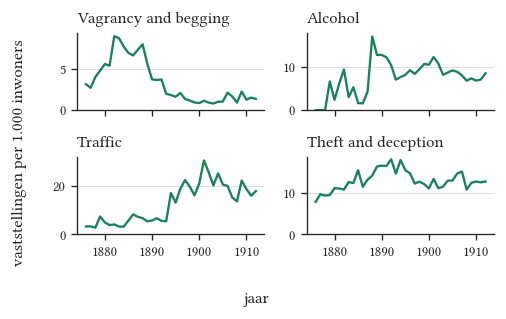

In [26]:
selectie = ["Vagrancy and begging", "Alcohol", "Traffic", "Theft and deception"]

fig, axes = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.62),
                         sharex=True)

for ax, naam in zip(axes.flat, selectie):
    ax.plot(per1000.columns, per1000.loc[naam],
            color=KLEUR_HOOFD, linewidth=1.4)
    ax.set_title(naam, fontsize=CORPS, loc="left")
    ax.set_ylim(bottom=0)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=CORPS_KLEIN)
    ax.set_xticks([1880, 1890, 1900, 1910])

fig.supylabel("vaststellingen per 1.000 inwoners", fontsize=CORPS)
fig.supxlabel("jaar", fontsize=CORPS)
fig.tight_layout()
plt.show()

leuren begint in: 1885


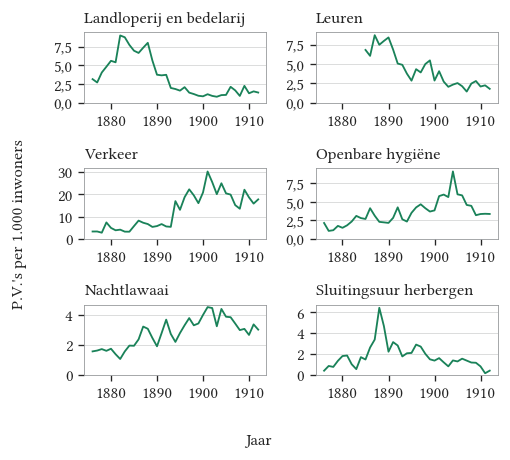

In [27]:
sub_rijen = {
    "Nachtlawaai":            173,
    "Sluitingsuur herbergen": 158,
}

extra = sheet0.iloc[list(sub_rijen.values())].loc[:, 1876:1912]
extra.index = list(sub_rijen)
extra_p1000 = extra.div(bev, axis=1) * 1000

nl_namen = {
    "Vagrancy and begging": "Landloperij en bedelarij",
    "Peddling":             "Leuren",
    "Traffic":              "Verkeer",
    "Public hygiene":       "Openbare hygiëne",
}

paneel = pd.concat([
    per1000.loc[list(nl_namen)].rename(index=nl_namen),
    extra_p1000,
])

volgorde = [
    "Landloperij en bedelarij",
    "Leuren",
    "Verkeer",
    "Openbare hygiëne",
    "Nachtlawaai",
    "Sluitingsuur herbergen"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.9),
    sharex=True
)

rij = paneel.loc["Leuren"]
eerste = rij[rij > 0].index.min()
paneel.loc["Leuren", :eerste-1] = np.nan
print("leuren begint in:", eerste)

for ax, naam in zip(axes.flat, volgorde):
    ax.plot(
        paneel.columns,
        paneel.loc[naam],
        color=KLEUR_A,
        linewidth=1.1
    )

    ax.set_title(naam, fontsize=CORPS, loc="left")
    ax.set_ylim(bottom=0)

    # Jaartallen onder elke grafiek
    ax.set_xticks([1880, 1890, 1900, 1910])
    ax.tick_params(axis="both", labelsize=CORPS)
    ax.tick_params(axis="x", labelbottom=True)

    ax.yaxis.grid(True)
    ax.xaxis.grid(False)
    ax.set_axisbelow(True)
    ax.locator_params(axis='y', nbins=4)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)
        spine.set_color('#96999B')

fig.supylabel(
    "P.V.'s per 1.000 inwoners",
    fontsize=CORPS
)

fig.supxlabel(
    "Jaar",
    fontsize=CORPS
)

fig.tight_layout()

pas_breedte_aan(plt.gcf())
plt.savefig(
    "../../fig/H2/2.2_PV_categorie.png",
    dpi=300
)

plt.show()


plt.show()